# Telco Customer Churn — Exploratory Data Analysis

Dataset: `WA_Fn-UseC_-Telco-Customer-Churn.csv` (IBM sample, 7043 rows x 21 cols).
Goal: characterize the customer base, the class imbalance, and the drivers of churn before building the model.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

ASSETS = os.path.join('..', 'app', 'assets')
os.makedirs(ASSETS, exist_ok=True)
DATA = os.path.join('..', 'data', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')

df = pd.read_csv(DATA)
print('shape:', df.shape)
df.head()

shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 1. Clean `TotalCharges`

`TotalCharges` is loaded as object because 11 rows contain a blank string. Coerce to numeric and impute the resulting NaNs with the median.

In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('NaN after coerce:', df['TotalCharges'].isna().sum())
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())
df['Churn_flag'] = (df['Churn'] == 'Yes').astype(int)

NaN after coerce: 11


## 2. Overall churn rate

Class imbalance is the headline finding: roughly 1 in 4 customers churn. Any model that always predicts "no churn" would still score ~74% accuracy, so we must weight metrics toward recall on the minority class and use SMOTE during training.

Churn rate: 26.54%


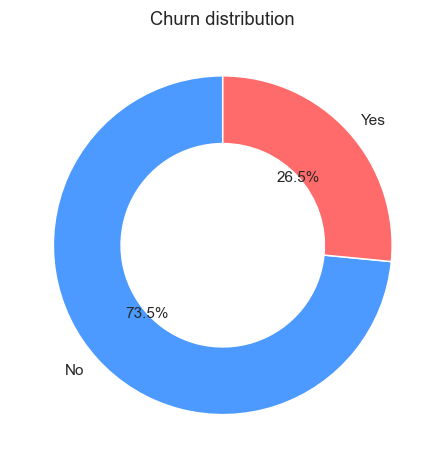

In [4]:
counts = df['Churn'].value_counts()
rate = counts['Yes'] / counts.sum()
print(f'Churn rate: {rate:.2%}')

fig, ax = plt.subplots(figsize=(5, 5))
wedges, texts, autotexts = ax.pie(counts.values, labels=counts.index,
    autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.4),
    colors=['#4C9AFF', '#FF6B6B'])
ax.set_title('Churn distribution')
plt.savefig(os.path.join(ASSETS, 'churn_donut.png'), bbox_inches='tight', dpi=150)
plt.show()

## 3. Churn rate by categorical drivers

Key findings:
- **Contract**: month-to-month customers churn at ~3x the rate of two-year customers — the single strongest categorical signal.
- **InternetService**: fiber-optic subscribers churn more than DSL users; customers with no internet service churn the least.
- **PaymentMethod**: electronic check users churn at the highest rate, suggesting friction or lower commitment vs. autopay.
- **SeniorCitizen**: senior customers churn at nearly double the rate of non-seniors.

C:\Users\mdajm\AppData\Local\Temp\ipykernel_32092\4108721936.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette='viridis')
C:\Users\mdajm\AppData\Local\Temp\ipykernel_32092\4108721936.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette='viridis')
C:\Users\mdajm\AppData\Local\Temp\ipykernel_32092\4108721936.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette='viridis')
C

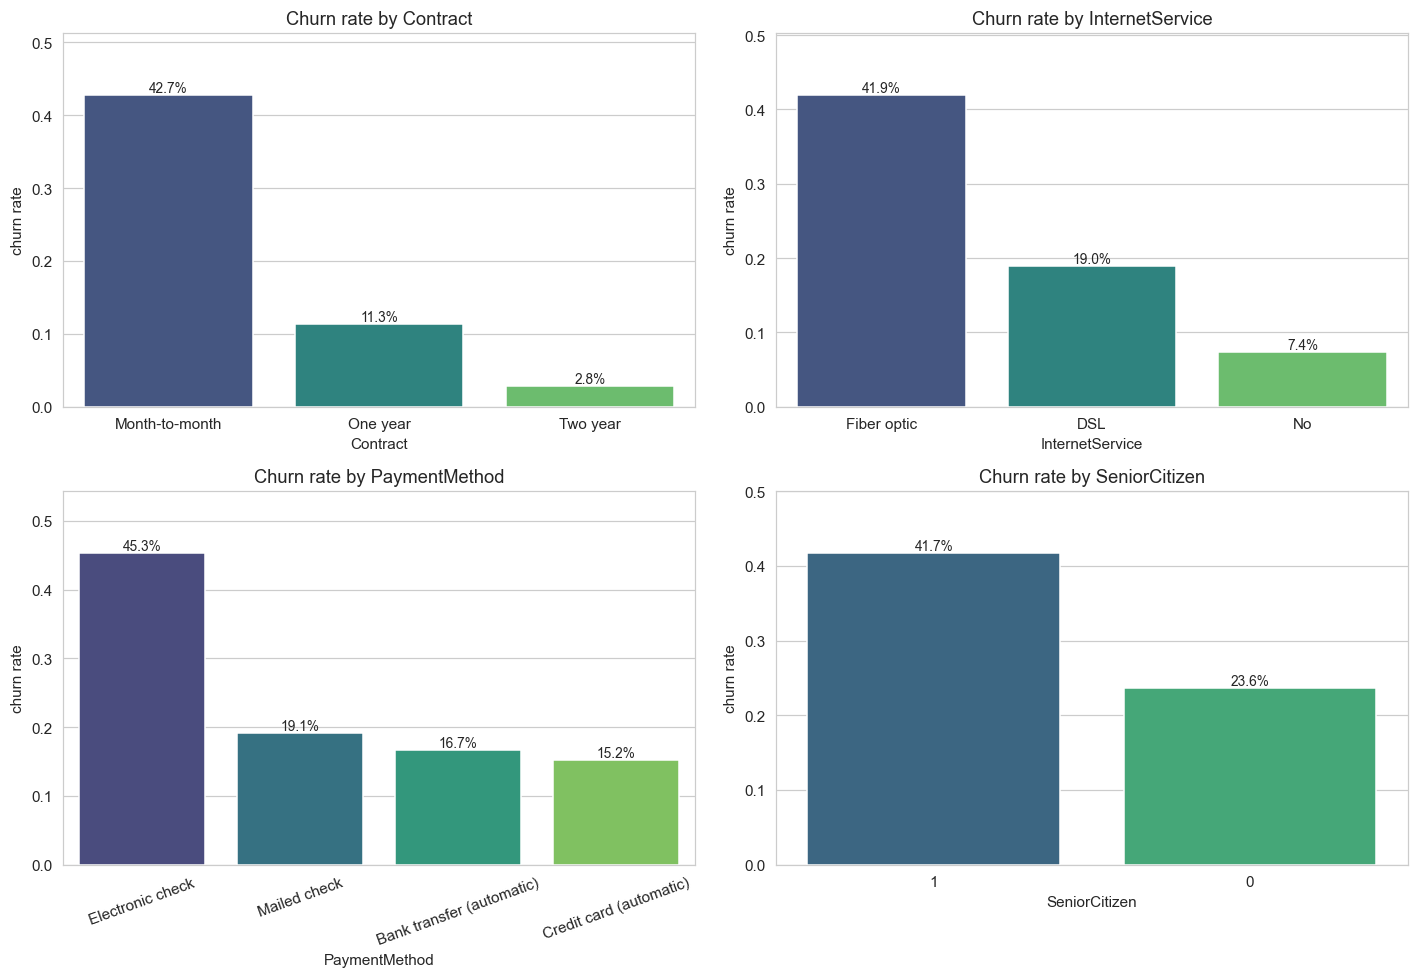

In [5]:
cats = ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, cats):
    rates = df.groupby(col)['Churn_flag'].mean().sort_values(ascending=False)
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, palette='viridis')
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('churn rate')
    ax.set_ylim(0, max(rates.values) * 1.2)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
    if col == 'PaymentMethod':
        ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(ASSETS, 'churn_by_category.png'), bbox_inches='tight', dpi=150)
plt.show()

## 4. Numeric distributions — churners vs non-churners

Findings:
- **tenure**: churners are concentrated in the first 12 months. Customers who survive past ~24 months rarely leave.
- **MonthlyCharges**: churners cluster around the $70–$110 range — higher bills correlate with churn.
- **TotalCharges**: skews low for churners, reinforcing that most churn happens early in the lifecycle.

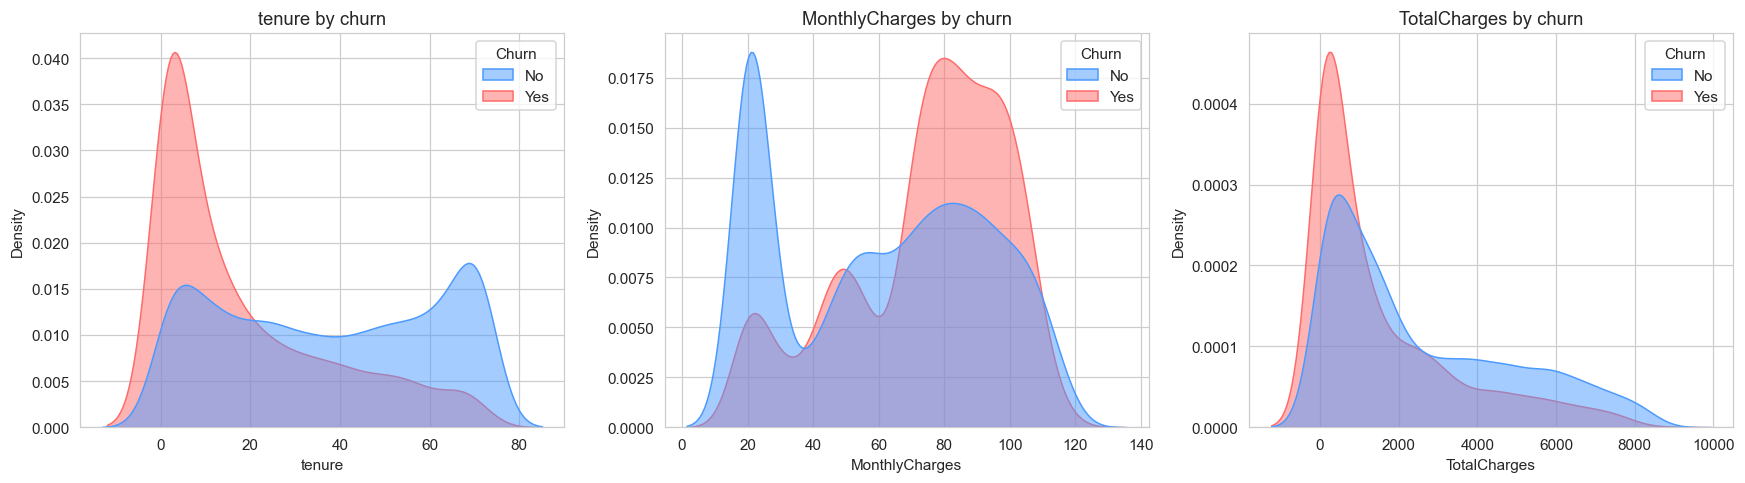

In [6]:
nums = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, nums):
    sns.kdeplot(data=df, x=col, hue='Churn', fill=True, common_norm=False,
                palette={'No': '#4C9AFF', 'Yes': '#FF6B6B'}, ax=ax, alpha=0.5)
    ax.set_title(f'{col} by churn')
plt.tight_layout()
plt.savefig(os.path.join(ASSETS, 'numeric_distributions.png'), bbox_inches='tight', dpi=150)
plt.show()

## 5. Correlation heatmap (numeric features)

`tenure` and `TotalCharges` are strongly correlated (long-tenured customers have naturally accumulated more spend). `tenure` shows the strongest negative correlation with churn; `MonthlyCharges` shows a positive one.

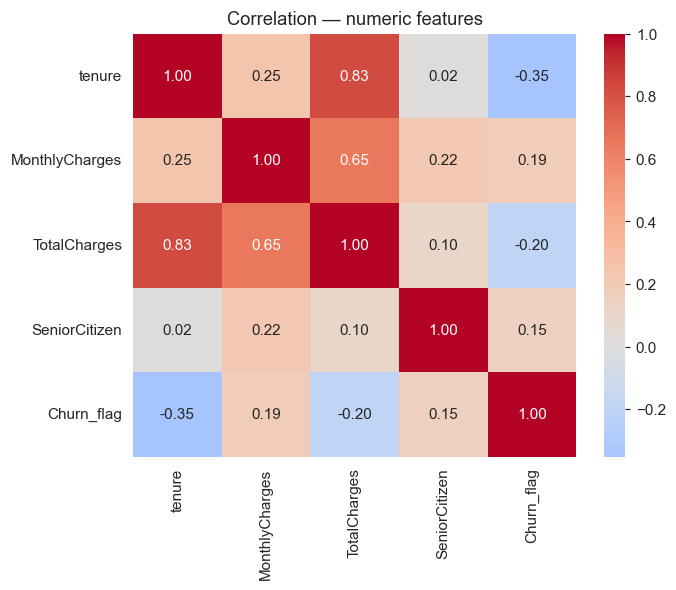

In [7]:
num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn_flag']]
corr = num_df.corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation — numeric features')
plt.savefig(os.path.join(ASSETS, 'correlation_heatmap.png'), bbox_inches='tight', dpi=150)
plt.show()

## Summary of findings

1. **Class imbalance** — 26.5% churn vs 73.5% retained. SMOTE on the training set only.
2. **Month-to-month contracts** are the single strongest churn signal.
3. **Tenure < 12 months** is the highest-risk segment.
4. **Higher monthly charges** correlate with churn.
5. **Fiber-optic** internet users churn more than DSL users.
6. **Electronic check** payment users churn most among payment methods.

Next: encode categoricals, split, apply SMOTE on train, fit scaler, persist artifacts (see `src/preprocess.py`).